# Ensemble Learning
**Part A:** Random Forest to predict car safety/acceptability  |  **Part B:** AdaBoost, Gradient Boosting, XGBoost and voting ensembles on Iris

Both datasets are downloaded from Kaggle using `kagglehub`.

In [7]:
%pip install -q kagglehub xgboost

Note: you may need to restart the kernel to use updated packages.


## Part A: Random Forest on the Car Evaluation Dataset
Each car is described by buying price, maintenance cost, doors, persons, luggage boot size and safety, and the target `class` says whether the car is `unacc`, `acc`, `good` or `vgood` (acceptability, which depends heavily on safety).

In [8]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

plt.style.use("seaborn-v0_8-whitegrid")

def kaggle_csv(handle, **kwargs):
    return pd.read_csv(glob.glob(os.path.join(kagglehub.dataset_download(handle), "*.csv"))[0], **kwargs)

cols = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
car = kaggle_csv("elikplim/car-evaluation-data-set", header=None, names=cols)   # file has no header row
car = car[car["buying"] != "buying"]                                              # safeguard in case a header exists

print(car.shape, "| missing values:", car.isnull().sum().sum())
print(car["class"].value_counts())
car.head()

(1728, 7) | missing values: 0
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


Test accuracy: 97.98%

              precision    recall  f1-score   support

         acc       0.94      0.97      0.96        77
        good       1.00      0.93      0.96        14
       unacc       0.99      0.99      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.98      0.95      0.97       346
weighted avg       0.98      0.98      0.98       346



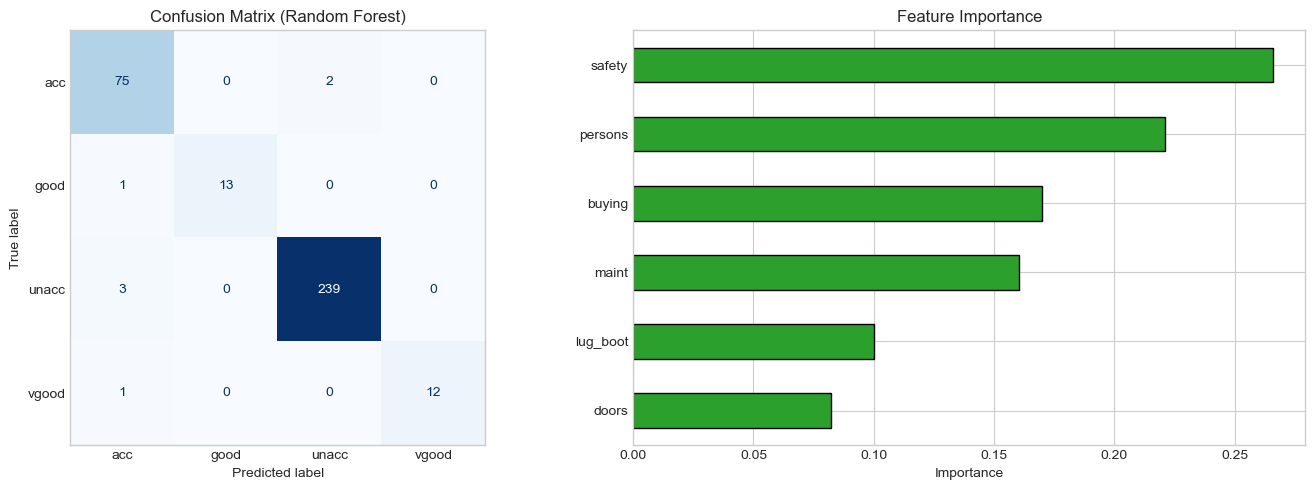

In [9]:
X = pd.get_dummies(car.drop(columns="class"))          # one-hot encode the categorical features
y = car["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)
pred = rf.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, pred):.2%}\n")
print(classification_report(y_test, pred))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion Matrix (Random Forest)"); ax[0].grid(False)

imp = pd.Series(rf.feature_importances_, index=X.columns)
imp = imp.groupby(lambda c: c.rsplit("_", 1)[0]).sum().sort_values()     # combine dummy columns per original feature
imp.plot(kind="barh", ax=ax[1], color="#2ca02c", edgecolor="black")
ax[1].set(title="Feature Importance", xlabel="Importance")
plt.tight_layout()
plt.show()

**Conclusion:** the Random Forest predicts car acceptability with high accuracy. The feature importance chart shows which attributes matter most; safety and the number of persons are expected to rank highest, since cars with low safety or only two seats are almost always unacceptable. The minority classes (`good`, `vgood`) are predicted less reliably because they have far fewer examples.

## Part B: AdaBoost, Gradient Boosting, XGBoost and Voting on Iris

In [10]:
iris = kaggle_csv("uciml/iris").drop(columns="Id")
Xi = iris.drop(columns="Species")
yi = LabelEncoder().fit_transform(iris["Species"])      # XGBoost needs numeric class labels

Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.2, random_state=42, stratify=yi)
print(iris.shape, "| missing values:", iris.isnull().sum().sum())

(150, 5) | missing values: 0


**Train the three boosting models and two voting ensembles** (hard voting = majority class, soft voting = average of predicted probabilities).

In [11]:
base = [
    ("AdaBoost", AdaBoostClassifier(n_estimators=100, random_state=42)),
    ("GBM",      GradientBoostingClassifier(random_state=42)),
    ("XGBoost",  XGBClassifier(eval_metric="mlogloss", random_state=42)),
]
models = dict(base)
models["Voting (hard)"] = VotingClassifier(base, voting="hard")
models["Voting (soft)"] = VotingClassifier(base, voting="soft")

rows = {}
for name, model in models.items():
    model.fit(Xi_train, yi_train)
    p = model.predict(Xi_test)
    rows[name] = {
        "Accuracy":  accuracy_score(yi_test, p),
        "Precision": precision_score(yi_test, p, average="macro"),
        "Recall":    recall_score(yi_test, p, average="macro"),
        "F1-score":  f1_score(yi_test, p, average="macro"),
        "CV accuracy (5-fold)": cross_val_score(model, Xi, yi, cv=5).mean(),
    }
results = pd.DataFrame(rows).T
results.round(4)

,Accuracy,Precision,Recall,F1-score,CV accuracy (5-fold)
AdaBoost,0.9333,0.9333,0.9333,0.9333,0.9533
GBM,0.9667,0.9697,0.9667,0.9666,0.9600
XGBoost,0.9333,0.9333,0.9333,0.9333,0.9533
Voting (hard),0.9667,0.9697,0.9667,0.9666,0.9600
Voting (soft),0.9667,0.9697,0.9667,0.9666,0.9533


**Compare the models.**

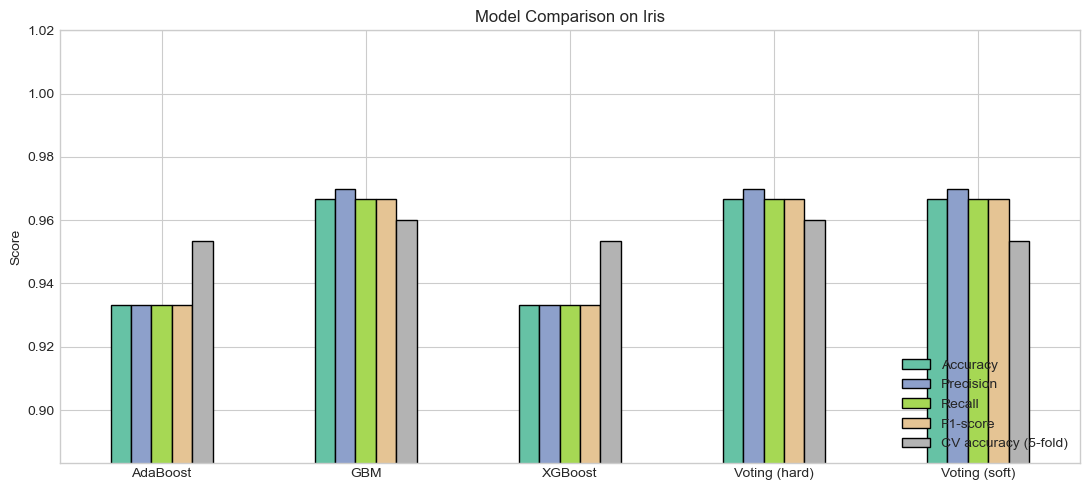

In [12]:
results.plot(kind="bar", figsize=(11, 5), edgecolor="black", rot=0, colormap="Set2")
plt.title("Model Comparison on Iris"); plt.ylabel("Score")
plt.ylim(results.min().min() - 0.05, 1.02)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Conclusion:** all three boosting models perform very well on Iris, with scores that are close to each other because the dataset is small and easy. Hard and soft voting combine the models and give stable results. With only 30 test samples, the 5-fold cross-validation accuracy is a more reliable basis for comparison than a single test split.